In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

months = np.arange(1, 13)

temperature = np.array([
    30, 35, 45, 58, 68, 78,
    85, 82, 72, 60, 45, 35
])

ice_cream = temperature * 12 + np.random.normal(0, 40, 12)
drownings = temperature * 0.5 + np.random.normal(0, 4, 12)

df_ice = pd.DataFrame({
    "Month": months,
    "Temperature": temperature,
    "IceCreamSales": ice_cream,
    "Drownings": drownings
})

df_ice.head()

,Month,Temperature,IceCreamSales,Drownings
0,1,30,379.868566,15.967849
1,2,35,414.469428,9.846879
2,3,45,565.907542,15.600329
3,4,58,756.921194,26.750850
4,5,68,806.633865,29.948676


In [14]:
correlation = df_ice["IceCreamSales"].corr(
    df_ice["Drownings"]
)

print("Correlation:", correlation)

Correlation: 0.9191254314603255


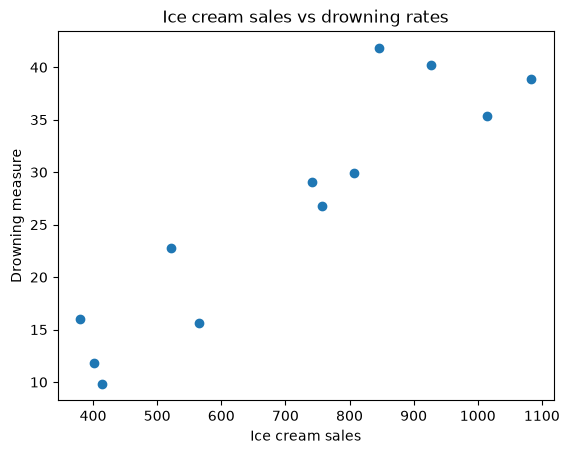

In [15]:
plt.scatter(
    df_ice["IceCreamSales"],
    df_ice["Drownings"]
)

plt.xlabel("Ice cream sales") 
plt.ylabel("Drowning measure")
plt.title("Ice cream sales vs drowning rates")
plt.show()

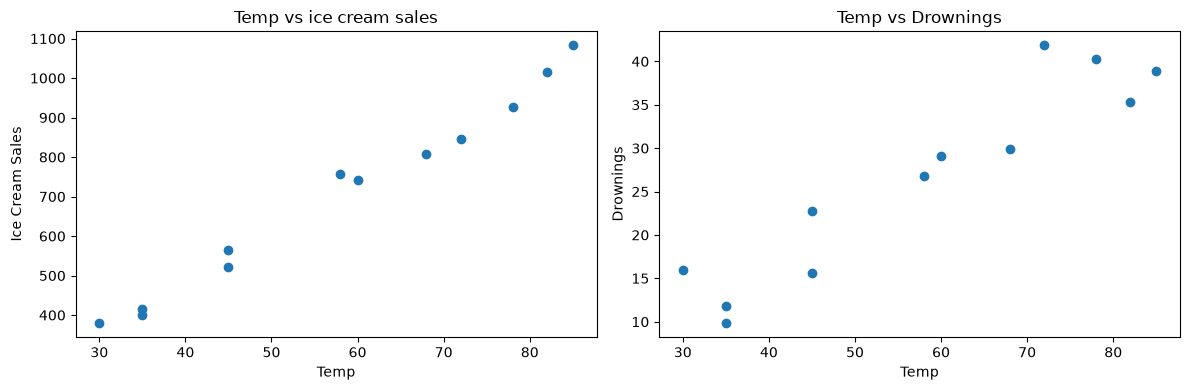

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))

axes[0].scatter(
    df_ice["Temperature"],
    df_ice["IceCreamSales"]
)

axes[0].set_title("Temp vs ice cream sales")
axes[0].set_xlabel("Temp")
axes[0].set_ylabel("Ice Cream Sales")

axes[1].scatter(
    df_ice["Temperature"],
    df_ice["Drownings"]
)

axes[1].set_title("Temp vs Drownings")
axes[1].set_xlabel("Temp")
axes[1].set_ylabel("Drownings")

plt.tight_layout()
plt.show()

In [17]:
import pandas as pd

data = {
    "Treatment": ["A", "A", "B", "B"],
    "Severity": ["Mild", "Severe", "Mild", "Severe"],
    "Successes": [81, 3, 234, 55],
    "Patients": [87, 13, 270, 80]
}

df_treatment = pd.DataFrame(data)

df_treatment["SuccessRate"] = (
    df_treatment["Successes"] /
    df_treatment["Patients"] * 100
)

df_treatment

,Treatment,Severity,Successes,Patients,SuccessRate
0,A,Mild,81,87,93.103448
1,A,Severe,3,13,23.076923
2,B,Mild,234,270,86.666667
3,B,Severe,55,80,68.750000


In [19]:
overall = df_treatment.groupby("Treatment")[
    ["Successes", "Patients"]
].sum()

overall["SuccessRate"] = (
    overall["Successes"] / 
    overall["Patients"] * 100
)

overall

,Successes,Patients,SuccessRate
Treatment,,,
A,84,100,84.000000
B,289,350,82.571429


In [20]:
df_treatment.pivot(
    index="Severity", 
    columns="Treatment",
    values="SuccessRate"
)

Treatment,A,B
Severity,,
Mild,93.103448,86.666667
Severe,23.076923,68.750000


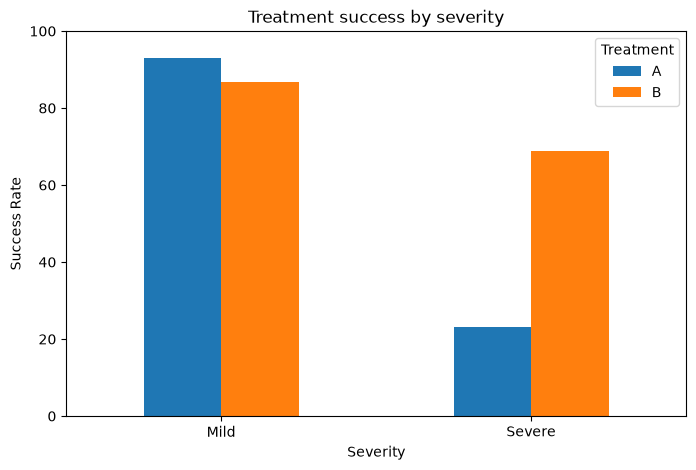

In [22]:
rates = df_treatment.pivot(
    index="Severity", 
    columns="Treatment",
    values="SuccessRate"
)

rates.plot(kind="bar", figsize=(8,5))
plt.ylabel("Success Rate")
plt.xlabel("Severity")
plt.title("Treatment success by severity")
plt.xticks(rotation=0)
plt.ylim(0,100)
plt.show()

In [23]:
data = {
    "Treatment": ["A", "A", "B", "B"],
    "Severity": ["Mild", "Severe", "Mild", "Severe"],
    "Successes": [81, 3, 19, 24],
    "Patients": [90, 10, 20, 80]
}

df_simpson = pd.DataFrame(data)

df_simpson["SuccessRate"] = (
    df_simpson["Successes"] /
    df_simpson["Patients"] * 100
)

print(df_simpson)

print("\nOverall rates:")

overall = df_simpson.groupby("Treatment")[
    ["Successes", "Patients"]
].sum()

overall["SuccessRate"] = (
    overall["Successes"] /
    overall["Patients"] * 100
)

print(overall)

  Treatment Severity  Successes  Patients  SuccessRate
0         A     Mild         81        90         90.0
1         A   Severe          3        10         30.0
2         B     Mild         19        20         95.0
3         B   Severe         24        80         30.0

Overall rates:
           Successes  Patients  SuccessRate
Treatment                                  
A                 84       100         84.0
B                 43       100         43.0


In [24]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.formula.api import ols

x = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]

datasets = {
    "I": [8.04, 6.95, 7.58, 8.81, 8.33, 9.96,
          7.24, 4.26, 10.84, 4.82, 5.68],
    "II": [9.14, 8.14, 8.74, 8.77, 9.26, 8.10,
           6.13, 3.10, 9.13, 7.26, 4.74],
    "III": [7.46, 6.77, 12.74, 7.11, 7.81, 8.84,
            6.08, 5.39, 8.15, 6.42, 5.73]
}

# Dataset IV has different X values
x4 = [8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8]
y4 = [6.58, 5.76, 7.71, 8.84, 8.47, 7.04,
      5.25, 12.50, 5.56, 7.91, 6.89]

In [26]:
for name, y in datasets.items():
    df = pd.DataFrame({"x": x, "y": y})

    model = ols("y ~ x", data=df).fit()

    print(name)
    print("Correlation:", df["x"].corr(df["y"]))
    print("R-squared:", model.rsquared)
    print("Slope:", model.params["x"])
    print()

I
Correlation: 0.81642051634484
R-squared: 0.666542459508775
Slope: 0.5000909090909091

II
Correlation: 0.8162365060002428
R-squared: 0.6662420337274844
Slope: 0.5

III
Correlation: 0.8162867394895984
R-squared: 0.6663240410665593
Slope: 0.49972727272727285

